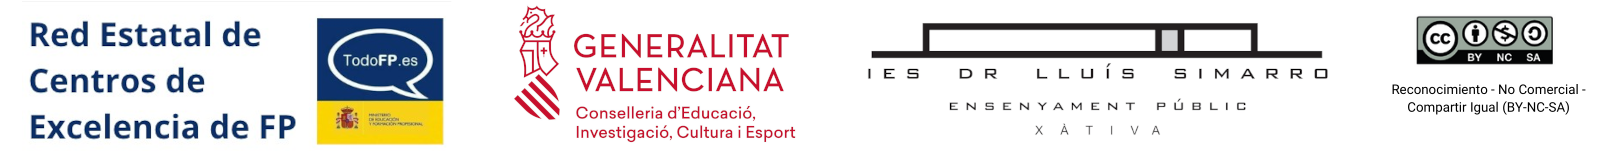

 ## **RESUMEN : Modelo de predicción de reseñas positivas o negativas de productos de Amazon:**

In [1]:
# Instalación de dependencias
!pip install scikit-learn pandas kagglehub

# Importar librerías
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer  # Para vectorización basada en conteos
from sklearn.naive_bayes import MultinomialNB  # Modelo Naive Bayes
from sklearn.model_selection import train_test_split  # Para dividir datos
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import time, os, json, re
from pprint import pprint  # Para mostrar resultados legibles
import kagglehub
import nltk
from nltk.corpus import stopwords

# Definir ruta del dataset y nombre del fichero
# Sabemos el valor de 'path' y 'file_path' después de haber descargado el dataset y visto donde se guarda la 1º vez
path = "/root/.cache/kagglehub/datasets/miriamodeyianypeter/sentiment-analysis-amazon-product-reviews/versions/1"
file_path = os.path.join(path, "Amazon-Product-Reviews - Amazon Product Review (1).csv")
# Verificar si el dataset ya existe para evitar descargas repetidas porque pesa mucho
if not os.path.exists(file_path):
    print("Dataset no encontrado. Descargando desde Kaggle...")
    path = kagglehub.dataset_download("miriamodeyianypeter/sentiment-analysis-amazon-product-reviews")
    file_path = os.path.join(path,  "Amazon-Product-Reviews - Amazon Product Review (1).csv")
    print(f"Dataset descargado en: {file_path}")
else:
    print(f"Dataset ya existe en: {file_path}")


Dataset no encontrado. Descargando desde Kaggle...


100%|██████████| 2.93M/2.93M [00:00<00:00, 68.8MB/s]

Extracting files...


Dataset descargado en: /root/.cache/kagglehub/datasets/miriamodeyianypeter/sentiment-analysis-amazon-product-reviews/versions/1/Amazon-Product-Reviews - Amazon Product Review (1).csv


In [2]:
# Cargar dataset
# - Usamos econding 'latin-1' por compatibilidad con el formato del CSV
df= pd.read_csv(file_path, encoding='latin-1')

In [3]:
df.head()

,marketplace,customer_id,review_id,product_id,product_parent,product_title,product_category,star_rating,helpful_votes,total_votes,vine,verified_purchase,review_headline,review_body,review_date,sentiment
0,US,11555559,R1QXC7AHHJBQ3O,B00IKPX4GY,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,5,0,0,N,Y,Five Stars,Great love it,2015-08-31,1
1,US,31469372,R175VSRV6ZETOP,B00IKPYKWG,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,3,0,0,N,N,Lots of ads Slow processing speed Occasionally...,Lots of ads<br />Slow processing speed<br />Oc...,2015-08-31,0
2,US,26843895,R2HRFF78MWGY19,B00IKPW0UA,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,5,0,0,N,Y,Well thought out device,Excellent unit. The versatility of this table...,2015-08-31,1
3,US,19844868,R8Q39WPKYVSTX,B00LCHSHMS,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,4,0,0,N,N,Not all apps/games we were looking forward to ...,I bought this on Amazon Prime so I ended up bu...,2015-08-31,1
4,US,1189852,R3RL4C8YP2ZCJL,B00IKPZ5V6,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,5,0,0,N,Y,Five Stars,All Amazon products continue to meet my expect...,2015-08-31,1


In [4]:

# Cargar y preprocesar dataset
df = df[["review_body", "sentiment"]].rename(columns={"review_body": "text"})  # Seleccionar texto y etiquetas

In [5]:
df.head()

,text,sentiment
0,Great love it,1
1,Lots of ads<br />Slow processing speed<br />Oc...,0
2,Excellent unit. The versatility of this table...,1
3,I bought this on Amazon Prime so I ended up bu...,1
4,All Amazon products continue to meet my expect...,1


In [6]:
# Función de limpieza para un solo texto
def limpiar_texto(text):
    # Ensure the input is a string
    text = str(text)
    # Convertir a minúsculas y eliminar saltos de línea
    sin_saltos = re.sub('\n', ' ', text.lower())
    # Eliminar URLs
    sin_url = re.sub(r'http\S+', '', sin_saltos)
    # Eliminar menciones (@usuario)
    sin_nickname = re.sub(r'@\S+', '', sin_url)
    # Eliminar hashtags (#hashtag)
    sin_hashtag = re.sub(r'#\S+', '', sin_nickname)
    # Eliminar signos de puntuación y caracteres especiales
    sin_character = re.sub(r'[^\w\s]', '', sin_hashtag)
    # Eliminar números
    sin_numero = re.sub(r'\d+', '', sin_character)
    # Reemplazar tildes
    sin_tildes = sin_numero.translate(str.maketrans('áéíóúü', 'aeiouu'))
    # Eliminar espacios al inicio y final
    return sin_tildes.strip()

# Aplicar limpieza inicial a la columna de texto
df["text"] = df["text"].apply(limpiar_texto)

# Descargar recursos de NLTK (solo la primera vez)
nltk.download('stopwords')

# Eliminar stopwords usando NLTK
stop_words = set(stopwords.words('english'))  # Cargar stopwords en inglés
def eliminar_stopwords(text):
    # Dividir el texto en palabras y filtrar stopwords
    words = text.split()
    cleaned_text = ' '.join([word for word in words if word not in stop_words])
    return cleaned_text

# Aplicar eliminación de stopwords
df["text"] = df["text"].apply(eliminar_stopwords)
print("Dataset con Texto limpio y sin stopwords...")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Dataset con Texto limpio y sin stopwords...


In [7]:
# No reducimos el dataset para entrenamiento
X = df["text"]  # Textos
y = df["sentiment"]  # Etiquetas
print(f"Dataset listo: {df.shape} (filas, columnas)")

Dataset listo: (30846, 2) (filas, columnas)


In [8]:
from imblearn.over_sampling import SMOTE
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report
import time

# Vectorización CountVectorizer con ajustes: aumentamos max_features e introducimos ngram_range y min_df
vectorizer = CountVectorizer(max_features=10000, ngram_range=(1, 2), min_df=5)
X_vec = vectorizer.fit_transform(X)  # Transformar textos a matriz de conteos absolutos
print(f"Matriz CountVectorizer creada: {X_vec.shape} (documentos, características)")

# Aplicar SMOTE para sobremuestreo de la clase minoritaria
smote = SMOTE(random_state=42)
X_vec_smote, y_smote = smote.fit_resample(X_vec, y)
print(f"Dataset después de SMOTE: {X_vec_smote.shape[0]} instancias")

# Dividir datos en entrenamiento y prueba después de SMOTE
X_train, X_test, y_train, y_test = train_test_split(X_vec_smote, y_smote, test_size=0.2, random_state=42)

# Calcular pesos de las muestras (mayor peso a la clase 0)
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

# Entrenar modelo Naive Bayes con sample_weight
start_time = time.time()
modelCountVectorizer_MultinomialNB = MultinomialNB()
modelCountVectorizer_MultinomialNB.fit(X_train, y_train, sample_weight=sample_weights)
print("Modelo Naive Bayes entrenado")

# Hacer predicciones de probabilidades
y_prob = modelCountVectorizer_MultinomialNB.predict_proba(X_test)[:, 1]
# Ajustar el umbral de decisión (por ejemplo, a 0.6)
threshold = 0.6
y_pred_adjusted = (y_prob >= threshold).astype(int)
# Evaluar el rendimiento con el umbral ajustado
print(classification_report(y_test, y_pred_adjusted))

Matriz CountVectorizer creada: (30846, 10000) (documentos, características)
Dataset después de SMOTE: 51534 instancias
Modelo Naive Bayes entrenado
              precision    recall  f1-score   support

           0       0.88      0.89      0.89      5180
           1       0.89      0.88      0.89      5127

    accuracy                           0.89     10307
   macro avg       0.89      0.89      0.89     10307
weighted avg       0.89      0.89      0.89     10307



Veamos todas las métricas:

In [9]:
y_pred= y_pred_adjusted

In [10]:
# Calcular métricas:
# Evalúan precisión global (accuracy), equilibrio entre falsos positivos/negativos
# (precision, recall), y capacidad predictiva (ROC-AUC).
metrics = {
    # Accuracy: Proporción de predicciones correctas (TP + TN) / Total.
    # Mide el rendimiento general.
    "accuracy": accuracy_score(y_test, y_pred),
    # Precision: Proporción de positivos predichos correctamente (TP / (TP + FP)).
    # Indica la exactitud de las predicciones positivas.
    "precision": precision_score(y_test, y_pred),
    # Recall: Proporción de positivos reales detectados (TP / (TP + FN)).
    # Mide la sensibilidad para capturar positivos reales.
    "recall": recall_score(y_test, y_pred),
    # F1-Score: Media armónica de Precision y Recall (2 * Precision * Recall / (Precision + Recall)).
    # Equilibra precisión y sensibilidad.
    "f1": f1_score(y_test, y_pred),
    # ROC-AUC: Área bajo la curva ROC, mide la capacidad de distinguir clases.
    # Cuanto mayor, mejor discriminación.
    "roc_auc": roc_auc_score(y_test, y_prob),
    # Matriz de Confusión: [ [TN, FP], [FN, TP] ].
    # TN: Negativos correctos, FP: Falsos positivos,
    # FN: Falsos negativos, TP: Positivos correctos.
    "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    "classification_report": classification_report(y_test, y_pred, output_dict=True)
}

# Mostrar métricas con documentación
print("\n--- Métricas CountVectorizer  y MultinomialNB ---")
print(f"Accuracy: {metrics['accuracy']:.4f}")
print("  - Definición: Proporción de predicciones correctas (TP + TN) / Total.")
print("  - Para qué sirve: Mide el rendimiento general del modelo.")
print(f"Precision: {metrics['precision']:.4f}")
print("  - Definición: Proporción de positivos predichos correctamente (TP / (TP + FP)).")
print("  - Para qué sirve: Indica la exactitud de las predicciones positivas, útil cuando evitar falsos positivos es importante.")
print(f"Recall: {metrics['recall']:.4f}")
print("  - Definición: Proporción de positivos reales detectados (TP / (TP + FN)).")
print("  - Para qué sirve: Mide la sensibilidad para capturar positivos, clave cuando no queremos perder casos positivos.")
print(f"F1-Score: {metrics['f1']:.4f}")
print("  - Definición: Media armónica de Precision y Recall (2 * Precision * Recall / (Precision + Recall)).")
print("  - Para qué sirve: Equilibra precisión y sensibilidad, ideal para datasets desbalanceados.")
print(f"ROC-AUC: {metrics['roc_auc']:.4f}")
print("  - Definición: Área bajo la curva ROC, mide la capacidad de distinguir clases.")
print("  - Para qué sirve: Cuanto mayor, mejor discriminación entre clases, útil para evaluar probabilidad predictiva.")
print("\nMatriz de Confusión:", metrics["confusion_matrix"])
print("  - Definición: [ [TN, FP], [FN, TP] ]. TN: Negativos correctos, FP: Falsos positivos, FN: Falsos negativos, TP: Positivos correctos.")
print("  - Para qué sirve: Muestra el detalle de los errores y aciertos del modelo por clase.")
print("\nReporte de Clasificación:")
print("  - Definición: Resumen detallado de métricas por clase (0 y 1) y promedios.")
print("  - Para qué sirve: Proporciona una visión completa del rendimiento por clase.")
pprint(metrics["classification_report"])


--- Métricas CountVectorizer  y MultinomialNB ---
Accuracy: 0.8880
  - Definición: Proporción de predicciones correctas (TP + TN) / Total.
  - Para qué sirve: Mide el rendimiento general del modelo.
Precision: 0.8917
  - Definición: Proporción de positivos predichos correctamente (TP / (TP + FP)).
  - Para qué sirve: Indica la exactitud de las predicciones positivas, útil cuando evitar falsos positivos es importante.
Recall: 0.8820
  - Definición: Proporción de positivos reales detectados (TP / (TP + FN)).
  - Para qué sirve: Mide la sensibilidad para capturar positivos, clave cuando no queremos perder casos positivos.
F1-Score: 0.8868
  - Definición: Media armónica de Precision y Recall (2 * Precision * Recall / (Precision + Recall)).
  - Para qué sirve: Equilibra precisión y sensibilidad, ideal para datasets desbalanceados.
ROC-AUC: 0.9190
  - Definición: Área bajo la curva ROC, mide la capacidad de distinguir clases.
  - Para qué sirve: Cuanto mayor, mejor discriminación entre clas

Comprobemos si lo hace bien para los mensajes iniciales que teniamos en el ejemplo de CountVectorizer+ Naives:

In [11]:
# Debemos pasarle los mensajes en inglés porque esta entrenado con un dataset en inglés
mensajesES = ["¡Me gusta este producto!", "Pésimo servicio, día horrible", "Gran experiencia hoy",
              "Muy decepcionado", "¡Qué producto tan genial!", "Totalmente decepcionado",
              "Producto de gran lentitud", "La experiencia no fue buena", "No gastes dinero en ese producto",
              "Gran frustración con el producto"]
mensajesEN = ["Love this product!", "Terrible service, horrible day", "Great experience today",
              "Very disappointed", "What a great product!", "Totally disappointed",
              "Very slow product", "Experience was not good", "Don't spend money on that product",
              "Major frustration with the product"]

# Iterar sobre mensajesEN para predicción
print("Predicciones con CountVectorizer y MultinomialNB:")
for i,msg_en in enumerate(mensajesEN):
    prediccion = modelCountVectorizer_MultinomialNB.predict(vectorizer.transform([msg_en]))[0]
    resultado = "positivo" if prediccion == 1 else "negativo"
    print(f"Frase: '{msg_en}' - Sentimiento: {resultado}")

Predicciones con CountVectorizer y MultinomialNB:
Frase: 'Love this product!' - Sentimiento: positivo
Frase: 'Terrible service, horrible day' - Sentimiento: negativo
Frase: 'Great experience today' - Sentimiento: positivo
Frase: 'Very disappointed' - Sentimiento: negativo
Frase: 'What a great product!' - Sentimiento: positivo
Frase: 'Totally disappointed' - Sentimiento: negativo
Frase: 'Very slow product' - Sentimiento: negativo
Frase: 'Experience was not good' - Sentimiento: negativo
Frase: 'Don't spend money on that product' - Sentimiento: negativo
Frase: 'Major frustration with the product' - Sentimiento: negativo



## **NOVEDAD: Guardando nuestro modelo de NLP:**

### Paso 1: Guardado básico (El “Modo Manual”)

<font color="red">[Diapositiva 3]</font>

In [12]:
import joblib

# Asumimos que 'modelCountVectorizer_MultinomialNB' y 'vectorizer'
# ya están entrenados (como en tu script)

# 1. Guardar el modelo
joblib.dump(modelCountVectorizer_MultinomialNB, 'modelo_sentimientos_nb.joblib')

# 2. Guardar el vectorizador
# (Este vectorizer SOLO sabe trabajar con texto limpio)
joblib.dump(vectorizer, 'vectorizer_sentimientos.joblib')

print("¡Modelo y vectorizador guardados por separado!")

¡Modelo y vectorizador guardados por separado!


### Paso 1: Predicción (Modo Manual)

In [13]:
import joblib

# 1. Cargar los objetos desde el disco
loaded_model = joblib.load('modelo_sentimientos_nb.joblib')
loaded_vectorizer = joblib.load('vectorizer_sentimientos.joblib')

# 2. Definir una frase (¡YA DEBE ESTAR LIMPIA Y SIN STOPWORDS!)
frase_limpia = "slow processing speed"

# 3. Aplicar la transformación (traducir a números)
frase_vec = loaded_vectorizer.transform([frase_limpia])

# 4. Predecir
prediccion = loaded_model.predict(frase_vec)
resultado = "Positivo" if prediccion[0] == 1 else "Negativo"

print(f"La predicción para '{frase_limpia}' es: {resultado}")

La predicción para 'slow processing speed' es: Negativo


###Paso 2 - Creando Transformadores Personalizados

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin
# (Asumimos que 'limpiar_texto' y 'eliminar_stopwords' están definidas anteriormente)

# Wrapper para la función de limpieza
class TextCleaner(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self # No hay nada que "aprender"
    def transform(self, X):
        # Aplicamos la limpieza a cada elemento de la entrada
        return [limpiar_texto(text) for text in X]

# Wrapper para la función de stopwords
class StopwordRemover(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self # No hay nada que "aprender"
    def transform(self, X):
        # Aplicamos la eliminación de stopwords
        return [eliminar_stopwords(text) for text in X]

###Paso 2 - El Pipeline (Re-entrenamiento desde Cero):

In [15]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split

# Volvemos a los datos crudos del script
# 1. Cargar datos crudos
df_raw = pd.read_csv(file_path, encoding='latin-1')
df_raw = df_raw[["review_body", "sentiment"]].rename(columns={"review_body": "text"})

X_raw = df_raw["text"]
y_raw = df_raw["sentiment"]
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

# 2. Definir los pasos (¡Todo nuevo!)
pipeline_completo = ImbPipeline([
    ('1_limpieza', TextCleaner()),
    ('2_stopwords', StopwordRemover()),
    ('3_vectorizer', CountVectorizer(max_features=10000, ngram_range=(1, 2), min_df=5)), # NUEVO Vectorizer
    ('4_smote', SMOTE(random_state=42)),
    ('5_clasificador', MultinomialNB()) # NUEVO Modelo
])

# 3. ¡Entrenamos TODO el pipeline de una sola vez!
print("Entrenando el pipeline completo con datos crudos...")
pipeline_completo.fit(X_train_raw, y_train_raw)
print("¡Pipeline entrenado!")

Entrenando el pipeline completo con datos crudos...
¡Pipeline entrenado!


###Paso 3 - Persistir el Pipeline (Modo PRO):

In [16]:
import joblib

# Guardamos el objeto pipeline ENTERO
joblib.dump(pipeline_completo, 'pipeline_sentimientos_completo.joblib')

print("¡Pipeline completo guardado en 'pipeline_sentimientos_completo.joblib'!")

¡Pipeline completo guardado en 'pipeline_sentimientos_completo.joblib'!


###Paso 3 - Usar el Pipeline:

In [ ]:
import joblib

# (Debes asegurarte de que las clases 'TextCleaner' y 'StopwordRemover'
#  y las funciones 'limpiar_texto' y 'eliminar_stopwords'
#  estén definidas en este script también)

# 1. Cargar el ÚNICO objeto pipeline
modelo_produccion = joblib.load('pipeline_sentimientos_completo.joblib')

# 2. Definir frases de entrada (¡SUCIAS, del mundo real!)
frases_sucias = [
    "Lots of ads<br />Slow processing speed<br />", # Tiene HTML
    "What a great product!",                  # Limpia
    "Terrible service, horrible day... #fail" # Con puntuación y hashtag
]

# 3. ¡Predecir directamente!
# El pipeline hará automáticamente:
#   1. '1_limpieza' -> .transform()
#   2. '2_stopwords' -> .transform()
#   3. '3_vectorizer' -> .transform()
#   4. '4_smote' -> (¡SE OMITE!)
#   5. '5_clasificador' -> .predict()
predicciones = modelo_produccion.predict(frases_sucias)

for frase, pred in zip(frases_sucias, predicciones):
    resultado = "Positivo" if pred == 1 else "Negativo"
    print(f"Frase: '{frase}' -> Predicción: {resultado}")

Frase: 'Lots of ads<br />Slow processing speed<br />' -> Predicción: Negativo
Frase: 'What a great product!' -> Predicción: Positivo
Frase: 'Terrible service, horrible day... #fail' -> Predicción: Negativo


###Paso 3 - Guardar CSV:

In [18]:
# guardamos el csv original
df_raw = pd.read_csv(file_path, encoding='latin-1')
df_raw.to_csv('amazon_sentiment.csv', index=False)
print("Dataset 'amazon_sentiment.csv' guardado correctamente.")


Dataset 'amazon_sentiment.csv' guardado correctamente.
